# 01 · Engineering drawings → JSON: baseline

**Dataset:** [`ecado/rfq-engineering-drawings`](https://huggingface.co/datasets/ecado/rfq-engineering-drawings): 2D engineering drawings (title block, dimensions with tolerances, GD&T callouts, surface finish, treatment, weld symbols, notes) with gold JSON in the same `gt_parse` format as CORD. The drawings look synthetic (clean renders, generated names and dates).

Metric: **JSON F1** (valid-JSON gate, then F1 over `(key, value)` leaf pairs; list order ignored), the dataset's own instruction, images ≤1200 px.

| Split | Drawings | Gold fields | Use |
|---|---|---|---|
| train | 480 | 18,030 | SFT data and few-shot examples |
| validation | 60 | 2,284 | development |
| **test** | **60** | **2,163** | **sealed evaluation** |

**Baseline definition.** Zero-shot GLM invents its own key names (`part_name`, `part_no`), so it scores 37.6%. The real baseline is **GLM 5.3 Flash with a one-shot schema prompt** (one *training* drawing's gold JSON as the exact format), which scores 79.8%. Every improvement is measured against that.

In [1]:
import asyncio, json, os, sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "eng_common.py").exists():
    HERE = Path("experiments/eng-drawings-extraction").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import eng_common as c
import eng_report as rep
rep.fv.apply_theme()
print({s: len(c.load_split(s)) for s in ("train", "validation", "test")}, "· API key set:", bool(os.getenv("FIREWORKS_API_KEY")))

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 480, 'validation': 60, 'test': 60} · API key set: True


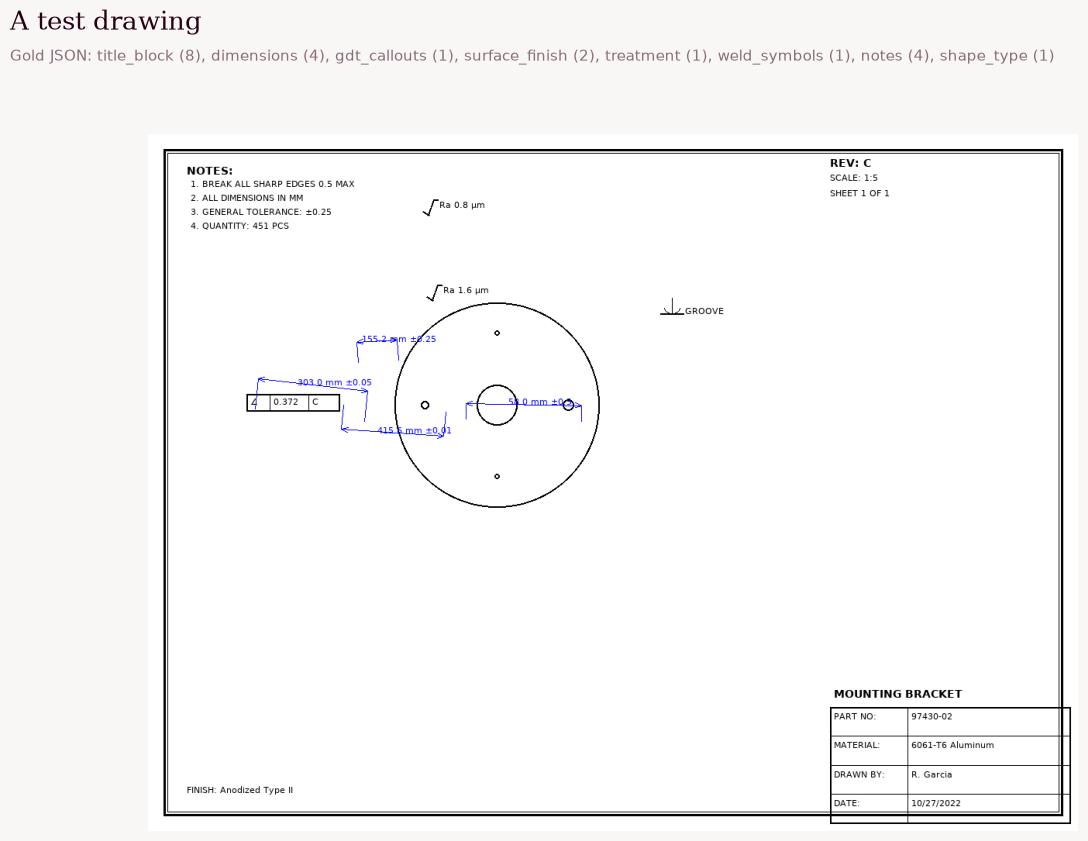

In [2]:
from PIL import Image
r = c.load_split("test")[0]
fig, ax = rep.fv.plt.subplots(figsize=(12, 9.6))
rep.fv._title(fig, "A test drawing", "Gold JSON: " + ", ".join(f"{k} ({len(v) if isinstance(v, list) else len(v) if isinstance(v, dict) else 1})" for k, v in r["gold"].items()))
ax.imshow(Image.open(HERE / r["image"])); ax.axis("off")
rep.fv.show(fig, "example_drawing")

## GLM: zero-shot (reference) and one-shot schema (baseline) · ≈$0.10

In [3]:
ONESHOT = c.oneshot_system()
await c.eval_model("glm", "glm_zero")
await c.eval_model("glm", "glm_oneshot", system=ONESHOT)

glm_zero: GLM 5.3 Flash on test · n=1 · to_run=0
glm_zero: mean JSON F1 37.6% · valid JSON 60/60
glm_oneshot: GLM 5.3 Flash on test · n=1 · to_run=0
glm_oneshot: mean JSON F1 79.8% · valid JSON 60/60


## Other models, same one-shot prompt · Kimi ≈$2, Muse ≈$1, Gemini ≈$2, Opus ≈$5, GPT ≈$1

In [4]:
for m in ("kimi", "muse", "gemini4", "opus55", "gpt61"):
    await c.eval_model(m, f"{m}_oneshot", system=ONESHOT)

kimi_oneshot: Kimi K3 on test · n=1 · to_run=0
kimi_oneshot: mean JSON F1 84.0% · valid JSON 60/60
muse_oneshot: Muse Spark on test · n=1 · to_run=0
muse_oneshot: mean JSON F1 84.7% · valid JSON 60/60
gemini4_oneshot: Gemini 4 Argon on test · n=1 · to_run=0
gemini4_oneshot: mean JSON F1 85.4% · valid JSON 60/60
opus55_oneshot: Claude Opus 5.5 on test · n=1 · to_run=0
opus55_oneshot: mean JSON F1 85.9% · valid JSON 60/60
gpt61_oneshot: GPT-6.1 Terra Pro on test · n=1 · to_run=0
gpt61_oneshot: mean JSON F1 80.7% · valid JSON 60/60


## Leaderboard

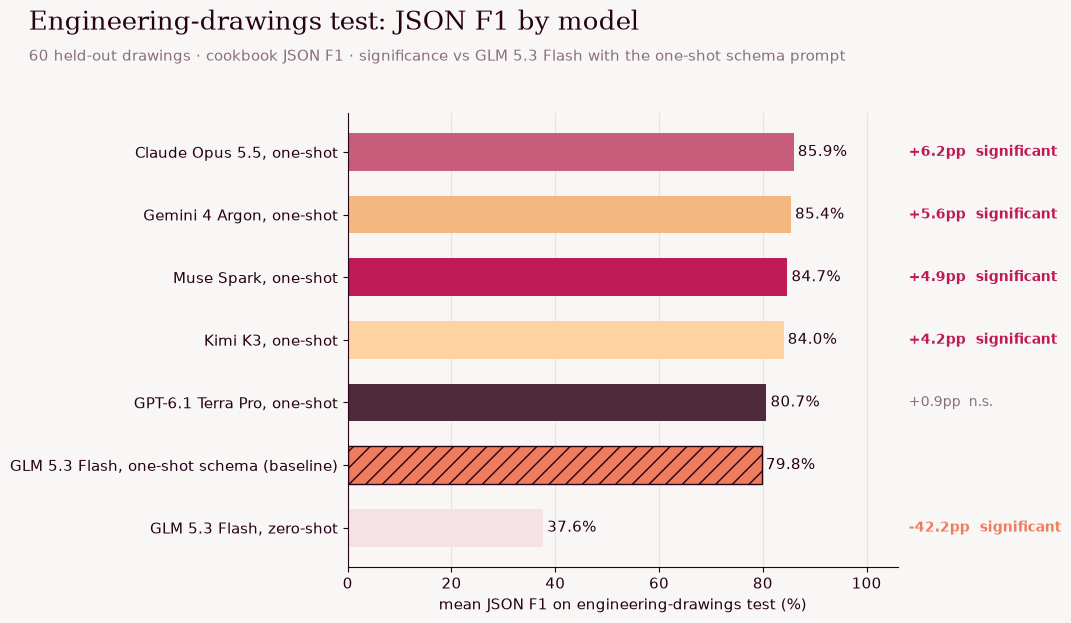

In [5]:
ALL = ["glm_zero", "glm_oneshot", "kimi_oneshot", "muse_oneshot", "gemini4_oneshot", "opus55_oneshot", "gpt61_oneshot"]
rep.leaderboard(ALL, "glm_oneshot", "Engineering-drawings test: JSON F1 by model",
                "60 held-out drawings · cookbook JSON F1 · significance vs GLM 5.3 Flash with the one-shot schema prompt")

In [6]:
rep.cost_table(ALL)

,mean F1,valid JSON,errors,cost $,$ per 1k drawings,median latency s
system,,,,,,
"GLM 5.3 Flash, zero-shot",37.6%,60/60,0,0.025,0.41,17.8
"GLM 5.3 Flash, one-shot schema (baseline)",79.8%,60/60,0,0.023,0.39,8.7
"Kimi K3, one-shot",84.0%,60/60,0,0.794,13.23,31.9
"Muse Spark, one-shot",84.7%,60/60,0,0.315,5.24,100.2
"Gemini 4 Argon, one-shot",85.4%,60/60,0,0.334,5.56,28.5
"Claude Opus 5.5, one-shot",85.9%,60/60,0,0.972,16.20,20.2
"GPT-6.1 Terra Pro, one-shot",80.7%,60/60,0,0.548,9.13,33.4


,mean F1,valid JSON,errors,cost $,$ per 1k drawings,median latency s
system,,,,,,
"GLM 5.3 Flash, zero-shot",37.6%,60/60,0,0.025,0.41,17.8
"GLM 5.3 Flash, one-shot schema (baseline)",79.8%,60/60,0,0.023,0.39,8.7
"Kimi K3, one-shot",84.0%,60/60,0,0.794,13.23,31.9
"Muse Spark, one-shot",84.7%,60/60,0,0.315,5.24,100.2
"Gemini 4 Argon, one-shot",85.4%,60/60,0,0.334,5.56,28.5
"Claude Opus 5.5, one-shot",85.9%,60/60,0,0.972,16.20,20.2
"GPT-6.1 Terra Pro, one-shot",80.7%,60/60,0,0.548,9.13,33.4


In [7]:
rep.significance_table([(t, "glm_oneshot") for t in ALL if t != "glm_oneshot"])

,drawings,fields,F1 a,F1 b,ΔF1 pp,fields only a,fields only b,McNemar p (fields),bootstrap 95% CI (drawings),significant,notes
pair,,,,,,,,,,,
"GLM 5.3 Flash, zero-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,37.6%,79.8%,-42.2,90,809,2.46e-145,"[-44.8, -39.5]",True,loss holds under both tests
"Kimi K3, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,84.0%,79.8%,4.2,175,60,3.11e-14,"[+2.5, +5.9]",True,GAIN holds under both tests
"Muse Spark, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,84.7%,79.8%,4.9,171,41,4.54e-20,"[+3.1, +6.7]",True,GAIN holds under both tests
"Gemini 4 Argon, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,85.4%,79.8%,5.6,211,56,2.46e-22,"[+3.9, +7.2]",True,GAIN holds under both tests
"Claude Opus 5.5, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,85.9%,79.8%,6.2,217,66,5.84e-20,"[+4.2, +8.1]",True,GAIN holds under both tests
"GPT-6.1 Terra Pro, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,80.7%,79.8%,0.9,118,128,0.5662,"[-0.9, +2.6]",False,within noise


,drawings,fields,F1 a,F1 b,ΔF1 pp,fields only a,fields only b,McNemar p (fields),bootstrap 95% CI (drawings),significant,notes
pair,,,,,,,,,,,
"GLM 5.3 Flash, zero-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,37.6%,79.8%,-42.2,90,809,2.46e-145,"[-44.8, -39.5]",True,loss holds under both tests
"Kimi K3, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,84.0%,79.8%,4.2,175,60,3.11e-14,"[+2.5, +5.9]",True,GAIN holds under both tests
"Muse Spark, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,84.7%,79.8%,4.9,171,41,4.54e-20,"[+3.1, +6.7]",True,GAIN holds under both tests
"Gemini 4 Argon, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,85.4%,79.8%,5.6,211,56,2.46e-22,"[+3.9, +7.2]",True,GAIN holds under both tests
"Claude Opus 5.5, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,85.9%,79.8%,6.2,217,66,5.84e-20,"[+4.2, +8.1]",True,GAIN holds under both tests
"GPT-6.1 Terra Pro, one-shot vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,80.7%,79.8%,0.9,118,128,0.5662,"[-0.9, +2.6]",False,within noise


**Stats.** Field-level McNemar: each of the 2,163 gold fields in the 60 test drawings is right or wrong for each system. Drawing-level bootstrap on mean F1 (resampling drawings). A gain counts only when both are significant.